In [71]:
# importo librerire che mi servono 
import pandas as pd
import numpy as np 
from IPython.display import display
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import seaborn as sns   
import matplotlib.pyplot as plt
import plotly.express as px
import os
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_absolute_error
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, precision_score, recall_score
from sklearn.cluster import KMeans

## TASK 1 - Python di base sui dati forniti

Sui quattro filr forinti svolgere i primi calcoli con strutture dati, cicli e funzioni python senza metodi di analisi Pandas

## Differenze tra lista, tupla, set e dizionario

- **Lista**: raccolta ordinata e modificabile, adatta a sequenze di elementi che cambiano.
- **Tupla**: come la lista ma immutabile, utile per dati fissi.
- **Set**: elimina automaticamente i duplicati ed è veloce per verificare l'appartenenza.
- **Dizionario**: coppie chiave-valore, adatto per recuperare un dato tramite una chiave.

In [3]:
### 1. Leggere products.csv e sales.json e convertirli con .to_dict(orient="records") in liste di dizionari; costruire regions come dizionario e il set delle categorie 

# leggo i file 
products = pd.read_csv("ESERCIZIO_M4-4-2_traccia_finale-products.csv")
sales = pd.read_json("ESERCIZIO_M4-4-2_traccia_finale-sales.json")
regions = pd.read_excel("ESERCIZIO_M4-4-2_traccia_finale-regions.xlsx")
 
# controllo i nomi delle colonne (utile per verificare Category e Price)
print(products.columns)
print(sales.columns)
print(regions.columns)

# converto in liste di dizionari
prod = products.to_dict(orient="records")
sal = sales.to_dict(orient="records")

print(prod)
print(sal)

# regions come dizionario: RegionID -> (State, SalesRegion)
reg = {
    r["RegionID"]: (r["State"], r["SalesRegion"])
    for r in regions.to_dict(orient="records")
}

print(reg)

# set delle categorie uniche, ricavato dai prodotti
categorie = {p["Category"] for p in prod}   # adatta il nome della colonna

print(categorie)

# verifica di appartenenza
print("Outdoor" in categorie)
print("Playstation 5" in categorie)

Index(['ProductID', 'ProductName', 'Category', 'ListPrice'], dtype='str')
Index(['SalesID', 'ProductID', 'RegionID', 'ResellerID', 'SalesDate',
       'Quantity', 'SalesAmount'],
      dtype='str')
Index(['RegionID', 'State', 'SalesRegion'], dtype='str')
[{'ProductID': 1, 'ProductName': 'Bici Junior', 'Category': 'Outdoor', 'ListPrice': 129.0}, {'ProductID': 2, 'ProductName': 'Bici BMX', 'Category': 'Outdoor', 'ListPrice': 189.0}, {'ProductID': 3, 'ProductName': 'Monopattino', 'Category': 'Outdoor', 'ListPrice': 79.0}, {'ProductID': 4, 'ProductName': 'Pallone Calcio', 'Category': 'Outdoor', 'ListPrice': 19.9}, {'ProductID': 5, 'ProductName': 'Racchette Beach', 'Category': 'Outdoor', 'ListPrice': 14.5}, {'ProductID': 6, 'ProductName': 'Puzzle 1000', 'Category': 'Giochi da tavolo', 'ListPrice': 17.9}, {'ProductID': 7, 'ProductName': "Gioco dell'Oca", 'Category': 'Giochi da tavolo', 'ListPrice': 12.5}, {'ProductID': 8, 'ProductName': 'Scacchi Legno', 'Category': 'Giochi da tavolo', 'ListP

In [4]:
### 2. con una list comprehension e un costrutto if/elif/else assegnare a ogni prodotto la fascia di prezzo: bassa dotto 20 euro, media fino a 60 euro, alta oltre

# definisco la funzione con il costrutto if/elif/else
def fascia_prezzo(prezzo):
    if prezzo <= 20:
        return "bassa"
    elif prezzo <= 60:
        return "media"
    else:
        return "alta"

# list comprehension: copio ogni dizionario aggiungendo la chiave "Fascia" per non modificare il dizionario originale  
prod_fasce = [
    {**p, "Fascia": fascia_prezzo(p["ListPrice"])}
    for p in prod
]

print(prod_fasce)

# controllo rapido: nome, prezzo e fascia
for p in prod_fasce:
    print(p["ProductName"], p["ListPrice"], "->", p["Fascia"])

[{'ProductID': 1, 'ProductName': 'Bici Junior', 'Category': 'Outdoor', 'ListPrice': 129.0, 'Fascia': 'alta'}, {'ProductID': 2, 'ProductName': 'Bici BMX', 'Category': 'Outdoor', 'ListPrice': 189.0, 'Fascia': 'alta'}, {'ProductID': 3, 'ProductName': 'Monopattino', 'Category': 'Outdoor', 'ListPrice': 79.0, 'Fascia': 'alta'}, {'ProductID': 4, 'ProductName': 'Pallone Calcio', 'Category': 'Outdoor', 'ListPrice': 19.9, 'Fascia': 'bassa'}, {'ProductID': 5, 'ProductName': 'Racchette Beach', 'Category': 'Outdoor', 'ListPrice': 14.5, 'Fascia': 'bassa'}, {'ProductID': 6, 'ProductName': 'Puzzle 1000', 'Category': 'Giochi da tavolo', 'ListPrice': 17.9, 'Fascia': 'bassa'}, {'ProductID': 7, 'ProductName': "Gioco dell'Oca", 'Category': 'Giochi da tavolo', 'ListPrice': 12.5, 'Fascia': 'bassa'}, {'ProductID': 8, 'ProductName': 'Scacchi Legno', 'Category': 'Giochi da tavolo', 'ListPrice': 34.0, 'Fascia': 'media'}, {'ProductID': 9, 'ProductName': 'Costruzioni 500', 'Category': 'Giocattoli', 'ListPrice': 39

In [5]:
### 3. scrivere la funzione fatturato_categoria(vedite, prodotti, categoria) che con un ciclo for somma SalesAmount della categoria, salta i valori mancanti  e restituisce il totlare con retrun 
def fatturato_categoria(vendite, prodotti, categoria):
    # ID dei prodotti che appartengono alla categoria richiesta
    ids_categoria = {p["ProductID"] for p in prodotti if p["Category"] == categoria}

    totale = 0                                # accumulatore, parte da zero
    for v in vendite:                         # v = un dizionario di vendita
        if v["ProductID"] in ids_categoria:   # solo vendite della categoria
            importo = v["SalesAmount"]
            if pd.isna(importo):              # valore mancante (NaN o None)
                continue                      # salta al prossimo giro
            totale += importo                 # somma
    return totale

# stampo il risultato per ogni categoria 
print(fatturato_categoria(sal, prod, "Outdoor"))
print(fatturato_categoria(sal, prod, "Giochi da tavolo"))
print(fatturato_categoria(sal, prod, "Giocattoli"))

331998.3999999998
53245.10000000001
174832.00000000003


In [6]:
### 4. con un ciclo while contare le transazioni necessarie a superare 10.000 euro di fatturato comulato; mostrare le prime cinque transazioni con vendite[:5]
soglia = 10000
cumulato = 0
contatore = 0     # transazioni usate finora
i = 0             # indice della transazione corrente

while cumulato <= soglia and i < len(sal):
    importo = sal[i]["SalesAmount"]
    if not pd.isna(importo):      # salto i valori mancanti
        cumulato += importo
        contatore += 1
    i += 1

if cumulato > soglia:
    print("Transazioni necessarie per superare", soglia, ":", contatore)
else:
    print("La soglia non viene raggiunta. Cumulato finale:", cumulato)

print("Fatturato cumulato:", cumulato)

# prime cinque transazioni
print(sal[:5])

Transazioni necessarie per superare 10000 : 52
Fatturato cumulato: 10164.8
[{'SalesID': 1194, 'ProductID': 6, 'RegionID': 7, 'ResellerID': 283, 'SalesDate': '2023-01-01', 'Quantity': 4.0, 'SalesAmount': 71.6}, {'SalesID': 859, 'ProductID': 6, 'RegionID': 8, 'ResellerID': 28, 'SalesDate': '2023-01-02', 'Quantity': 7.0, 'SalesAmount': nan}, {'SalesID': 1747, 'ProductID': 12, 'RegionID': 3, 'ResellerID': 281, 'SalesDate': '2023-01-02', 'Quantity': 2.0, 'SalesAmount': 118.0}, {'SalesID': 279, 'ProductID': 3, 'RegionID': 7, 'ResellerID': 128, 'SalesDate': '2023-01-02', 'Quantity': 3.0, 'SalesAmount': nan}, {'SalesID': 1470, 'ProductID': 1, 'RegionID': 6, 'ResellerID': 137, 'SalesDate': '2023-01-04', 'Quantity': 4.0, 'SalesAmount': nan}]


## TASK 2 - Lettura e ispezione dei dati
Leggere i quattro file in DataFrame e descriverne struttura e contenuto prima di qualsiasi modifica

## Differenze tra Series e DataFrame, e tra .loc[] e .iloc[]

- Un **DataFrame** è formato da più **Series** affiancate, una per ogni colonna, che condividono lo stesso indice.
- `.loc[]` seleziona per etichetta quindi cerca quali righe o quali colonne si chiamano in un certo modo. 
- `.iloc[]`seleziona in base alla posizione, quindi ci dice quali righe e colonne si trona in una certa posizione. 

In [7]:
### 1. Leggere i file con pd.read_csv(), pd.read_excel() e pd.read_json e riportare per ciscuno .shape, .info(), .head() e .tail()

# leggo i file 
sales = pd.read_json("ESERCIZIO_M4-4-2_traccia_finale-sales.json")
reseller = pd.read_csv("ESERCIZIO_M4-4-2_traccia_finale-resellers.csv")
region = pd.read_excel("ESERCIZIO_M4-4-2_traccia_finale-regions.xlsx")
products = pd.read_csv("ESERCIZIO_M4-4-2_traccia_finale-products.csv")

# .shape
print("sales shape:", sales.shape)
print("reseller shape:", reseller.shape)
print("region shape:", region.shape)
print("products shape:", products.shape)

# .info()
sales.info()
reseller.info()
region.info()
products.info()

# .head()
print("sales head:", sales.head())
print("reseller head:", reseller.head())
print("region head:", region.head())
print("product head:", products.head())

# .tail()
print("sales tail:", sales.tail())
print("reseller tail:", reseller.tail())
print("region tail:", region.tail())
print("products tail:", products.tail())

sales shape: (2000, 7)
reseller shape: (300, 7)
region shape: (9, 3)
products shape: (12, 4)
<class 'pandas.DataFrame'>
RangeIndex: 2000 entries, 0 to 1999
Data columns (total 7 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   SalesID      2000 non-null   int64  
 1   ProductID    2000 non-null   int64  
 2   RegionID     2000 non-null   int64  
 3   ResellerID   2000 non-null   int64  
 4   SalesDate    2000 non-null   str    
 5   Quantity     1900 non-null   float64
 6   SalesAmount  1900 non-null   float64
dtypes: float64(2), int64(4), str(1)
memory usage: 129.0 KB
<class 'pandas.DataFrame'>
RangeIndex: 300 entries, 0 to 299
Data columns (total 7 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   ResellerID          300 non-null    int64  
 1   RegionID            300 non-null    int64  
 2   Ordini12m           300 non-null    int64  
 3   GiorniUltimoOrdine  300 non-nul

In [8]:
### 2. con .describe() individuare minimo, massimo e media di Quantity e SalesAmount convertire le due colonne in array NumPy e calcolare con un'operazione vettoriale il prezzo unitario di ogni vendita

# seleziono e stampo solo le due colonne che mi interessano 
print(sales[["Quantity", "SalesAmount"]].describe())

# converto le due colonne in array NumPy
quantity = sales["Quantity"].to_numpy()
sales_amount = sales["SalesAmount"].to_numpy()

# stampo per vedere se la converione è avvenuta
print(type(quantity))
print(type(sales_amount))

# calcolo del prezzo unitario con operazione vettoriale
prezzo_unitario = sales_amount / quantity

print(prezzo_unitario)

          Quantity  SalesAmount
count  1900.000000  1900.000000
mean      4.966316   294.776579
std       2.206535   305.261212
min       1.000000    12.500000
25%       3.000000    89.000000
50%       5.000000   177.000000
75%       6.000000   387.000000
max      14.000000  2457.000000
<class 'numpy.ndarray'>
<class 'numpy.ndarray'>
[17.9  nan 59.  ... 19.9 19.9 39.9]


In [9]:
### 3. selezionare con .loc[] e una maschera booleana i prodotti di una categoria con ListPrice superiore a 30 euro; con .iloc[] le righe da 10 a 19 e le prime tre colonne 

# maschera booleana: True solo dove entrambe le condizioni sono vere
maschera = (products["Category"] == "Outdoor") & (products["ListPrice"] > 30)

# .loc[] con la maschera
outdoor_mask = products.loc[maschera]
print(outdoor_mask)

# .iloc[]: righe da 10 a 19 e prime tre colonne 
subsample = products.iloc[10:20, 0:3] # 20 e 3 sono esclusi
print(subsample)

   ProductID  ProductName Category  ListPrice
0          1  Bici Junior  Outdoor      129.0
1          2     Bici BMX  Outdoor      189.0
2          3  Monopattino  Outdoor       79.0
    ProductID    ProductName    Category
10         11       Robot RC  Giocattoli
11         12  Macchinina RC  Giocattoli


## TASK 3a - Dati mancanti, filtri e ordinamento

Rendere il DataFrame delle vendite pronto per le analisi, trattando i valori mancanti e isolando i sottoinsiemi richiesti. 
 
 - **Imputazione**: consiste nel sostituire i valori mancanti con valori stimati per ridurre la perdita di informazione. 
 - **Media**: per variabili numeriche con distribuzione circa simmetrica e senza outlier, tuttavia riduce la varianza e può alterare la distribuzione. 
 - **Mediana**: preferibile per variabili numeriche con distribuzione asimmetrica o presenza di outlier, perché meno influenzata da valori estremi. riduce la variabilità e può aumentare la concentrazione di valori intorno alla mediana. 
 - **Eliminazione**: quando le osservazioni sono poche e la loro rimozione non introduce distorsioni rilevanti. 

In [10]:
### 1. contare NaN per colonna con .isna().sum() e calcoalre la percentuale sul numero totale di righe 

sales_NaN = sales.isna().sum() 
print(sales_NaN) 

percent_NaN = (sales.isna().mean() * 100).round(2)
print(percent_NaN)

# il risultato torna in quanto troviamo il 5% di NaN in Qauntity e SalesAmount che corrisponde a 100 records NaN su 2000 per quelle variabili

SalesID          0
ProductID        0
RegionID         0
ResellerID       0
SalesDate        0
Quantity       100
SalesAmount    100
dtype: int64
SalesID        0.0
ProductID      0.0
RegionID       0.0
ResellerID     0.0
SalesDate      0.0
Quantity       5.0
SalesAmount    5.0
dtype: float64


In [11]:
### 2. imputare Quantity con la mediana della colonna tramite fillna() ed eliminare con dropna() le righe di SalesAmount mancanti, dichiarando il numero di righe rimosse 

# mi sono sovrascritto nell'oggetto Sales il DF per mantenre un di di backup 
Sales = sales

# applico sulla colonna Qauntity il fillna() calcolando la mediana e inserendo il valore mediano dove è NaN
Sales['Quantity'] = Sales['Quantity'].fillna(Sales['Quantity'].median())

# il dorpna() lo applico sul df con il subset, perché in questo modo si eliminano tutte le righe dove SalesAmount è NaN
Sales = Sales.dropna(subset=['SalesAmount'])

# confronto righe elimniate 
print("righe prima:", len(sales))
print("righe dopo:", len(Sales))

righe prima: 2000
righe dopo: 1900


In [12]:
### 3. con .query() estrarre le transazioni con SalesAmount superiore al 90° percentile (quantile 0.9) e ordinarle con sort_values() per data crescente e importo descrescente 

# seleziono la colonna SA e calcolo il 90° percentile 
percentile_90 = Sales["SalesAmount"].quantile(0.9)
print(percentile_90)

# estraggo le transazioni con importo superiore al 90° percentile
trans = Sales.query("SalesAmount > @percentile_90")

# ordino per data crescente e importo descrescente 
trans = trans.sort_values(
    by=["SalesDate", "SalesAmount"],
    ascending=[True, False]
)

trans.head(10) # la data ha la priorità sull'importo quindi è normale che la colonna importono non risulti ordinata in ordine decrescente 


756.0


,SalesID,ProductID,RegionID,ResellerID,SalesDate,Quantity,SalesAmount
32,1045,2,4,82,2023-01-16,6.0,1134.0
49,1872,2,7,204,2023-01-25,5.0,945.0
52,1639,1,3,299,2023-01-27,9.0,1161.0
102,296,2,9,202,2023-02-25,5.0,945.0
118,1462,2,2,224,2023-03-03,5.0,945.0
121,1221,1,8,149,2023-03-05,8.0,1032.0
123,1753,2,8,151,2023-03-05,5.0,945.0
168,283,2,2,100,2023-03-30,11.0,2079.0
217,1679,1,4,22,2023-04-27,5.0,774.0
221,832,2,4,82,2023-04-28,6.0,1134.0


## TASK 3b - Aggregazione e combinazione dei DataFrame
Costruire una tabella unica delle vendite e calcolare il fatturato per le principali chiavi di analisi

- `.merge()`: unisce DataFrame sulla base di una o più colonne chiave comuni. 
- `.join()`: unisce DataFrame principalmente tramite gli indici, ma può utilizzare anche una colonna del DataFrame chiamante con on.
- `.concat()`: concatena DataFrame lungo un asse: verticalmente (axis=0), aggiungendo righe, oppure orizzontalmente (axis=1), affiancando colonne e non richiede una chiave esplicita

In [13]:
### 1. unire sales con products e regions tramite merge() su productID e RegionID (how="left") e verificare che il numero di righe resti quello di sales 

# faccio i merge dei 3 datasets
first_merge = pd.merge(sales, products, on = "ProductID", how = "left")
final_merge = pd.merge(first_merge, regions, on = "RegionID", how = "left")

# controllo del numero di righe 
print("native df:", len(sales))
print("merge df:", len(final_merge))

native df: 2000
merge df: 2000


In [14]:
### 2. con groupby() e agg() calcolare fatturato totale, quantità totale e numero di transazioni per category e per SalesRegion, ordinati per fatturato decrescente 

risultato = (
    final_merge.groupby(['Category', 'SalesRegion'])
    .agg(
        fatturato_totale=('SalesAmount', 'sum'),
        quantita_totale=('Quantity', 'sum'),
        numero_transazioni=('SalesID', 'count')
    )
    .sort_values(by='fatturato_totale', ascending=False)
)

print(risultato)


                                fatturato_totale  quantita_totale  \
Category         SalesRegion                                        
Outdoor          Centro Europa          123174.8           1485.0   
                 Nord Europa            111980.6           1364.0   
                 Sud Europa              96843.0           1145.0   
Giocattoli       Nord Europa             61212.8           1150.0   
                 Centro Europa           57441.2           1130.0   
                 Sud Europa              56178.0           1150.0   
Giochi da tavolo Centro Europa           20446.2            988.0   
                 Nord Europa             16995.6            807.0   
                 Sud Europa              15803.3            717.0   

                                numero_transazioni  
Category         SalesRegion                        
Outdoor          Centro Europa                 297  
                 Nord Europa                   277  
                 Sud Europa 

**La categoria con il fatturato più alto è "Outdoor", con un fattura totale di 331998.4 (valore che coincide anche con i risultati ottenuti nel task 1)**

In [15]:
### 3. separare le vendite 2025 dalle altre con un filtro e ricomporle con pd.concat(), verificando che la somma delle righe coincida con l'originale

# Separo le vendite del 2025 dalle altre
vendite_2025 = final_merge[                       # qui chiedo a python di selezionare soltanto le righe in cui la data è compresa dal 1 gennaio al 31 dicembre 2025 (le condizioni devono essere vere entrmabe)
    (final_merge['SalesDate'] >= '2025-01-01') &
    (final_merge['SalesDate'] < '2026-01-01')
]

altre_vendite = final_merge[                       # qui seleziono tutto quello che è rimasto fuori dal primo gruppo (basta che sia vera una delle due condizioni)
    (final_merge['SalesDate'] < '2025-01-01') |
    (final_merge['SalesDate'] >= '2026-01-01')
]

# ricompongo il DataFrame con pd.concat()
final_merge_ricomposto = pd.concat(
    [vendite_2025, altre_vendite]
)

# verifico il numero di righe
print("Righe originali:", len(final_merge))
print("Righe vendite 2025:", len(vendite_2025))
print("Righe altre vendite:", len(altre_vendite))
print("Righe ricomposte:", len(final_merge_ricomposto))

# verifico che il numero di righe coincida
print(
    "Verifica:",
    len(final_merge) == len(final_merge_ricomposto)
)

Righe originali: 2000
Righe vendite 2025: 672
Righe altre vendite: 1328
Righe ricomposte: 2000
Verifica: True


## TASK 3c - Serei temporali di vendita
analizzare l'andamento delle vendite nel tempo a partire dal campo SalesDate

In [21]:
### 1. convertire SalesDate con pd.to_datetime() e verificare il nuovo tipo con .dtypes

# conversione della colonna SalesDate in dt
sales["SalesDate"] = pd.to_datetime(sales["SalesDate"])

# verifica
print(sales["SalesDate"].dtypes)


datetime64[us]


In [24]:
### 2.  con l'accessor .dt estrarre anno, mese e giorno della settimana in tre nuove colonne 

sales["Year"] = sales["SalesDate"].dt.year
sales["Month"] = sales["SalesDate"].dt.month
sales["DayOfWeek"] = sales["SalesDate"].dt.day_name()

# check 
sales[["SalesDate", "Year", "Month", "DayOfWeek"]].head()


,SalesDate,Year,Month,DayOfWeek
0,2023-01-01,2023,1,Sunday
1,2023-01-02,2023,1,Monday
2,2023-01-02,2023,1,Monday
3,2023-01-02,2023,1,Monday
4,2023-01-04,2023,1,Wednesday


In [25]:
### 3. calcolare il fatturato mensile con groupby() su un anno e mese e la variazione percentuale tra mesi consecutivi con pct_change()
monthly = (
    sales.groupby(["Year", "Month"])["SalesAmount"]
    .sum()
    .reset_index(name="Revenue")
    .sort_values(["Year", "Month"])
)

monthly["PctChange"] = monthly["Revenue"].pct_change()

# opzionale: in percentuale leggibile
monthly["PctChange_%"] = (monthly["PctChange"] * 100).round(2)

display(monthly)

,Year,Month,Revenue,PctChange,PctChange_%
0,2023,1,11499.8,NaN,NaN
1,2023,2,9414.9,-0.181299,-18.13
2,2023,3,14917.2,0.584425,58.44
3,2023,4,11077.9,-0.257374,-25.74
4,2023,5,10806.7,-0.024481,-2.45
5,2023,6,11637.3,0.076860,7.69
6,2023,7,10161.0,-0.126859,-12.69
7,2023,8,15387.5,0.514369,51.44
8,2023,9,14361.2,-0.066697,-6.67
9,2023,10,13340.5,-0.071073,-7.11


In [ ]:
### 4. aggiungere la colonna booleana recente: True se la vendita è avvenuta entro 180 giorni dall'ultima data presente nel dataset, altrimenti False

# check dell'ultima data presente nel DF
ultima_data = sales["SalesDate"].max() # 2025-12-30 00:00:00

# creo una data soglia 
soglia = ultima_data - pd.Timedelta(days=180) # 2025-07-03 00:00:00

# creo la colonna 
sales["Recente"] = sales["SalesDate"] >= soglia

# show
display(sales)

2025-07-03 00:00:00


,SalesID,ProductID,RegionID,ResellerID,SalesDate,Quantity,SalesAmount,Year,Month,DayOfWeek,Recente
0,1194,6,7,283,2023-01-01,4.0,71.6,2023,1,Sunday,False
1,859,6,8,28,2023-01-02,7.0,NaN,2023,1,Monday,False
2,1747,12,3,281,2023-01-02,2.0,118.0,2023,1,Monday,False
3,279,3,7,128,2023-01-02,3.0,NaN,2023,1,Monday,False
4,1470,1,6,137,2023-01-04,4.0,NaN,2023,1,Wednesday,False
...,...,...,...,...,...,...,...,...,...,...,...
1995,326,3,1,280,2025-12-27,4.0,316.0,2025,12,Saturday,True
1996,394,7,2,256,2025-12-29,5.0,62.5,2025,12,Monday,True
1997,196,4,8,50,2025-12-29,5.0,99.5,2025,12,Monday,True
1998,878,4,4,27,2025-12-30,8.0,159.2,2025,12,Tuesday,True


## TASK 4 - Visualizzazione e storytelling
Produrre tre grafici obbligatori e uno opzionale, ciasuna risposta a una domanda di business, scegliendo il tipo di grafico in base al tipo di dato.

**Criterio di scelta del grafico**
- **Andamento nel tempo → linee:** serve quando i dati seguono un ordine cronologico (giorni, mesi, anni) e voglio vedere se crescono, calano o hanno dei picchi. 
- **Confronto tra categorie → barre:** serve quando ho gruppi separati e voglio capire quale è più alto o più basso. 
- **Distribuzione → boxplot:** serve quando voglio vedere come si distribuiscono i valori di una variabile: dove sta la mediana, quanto sono dispersi i dati e se ci sono outlier. 
- **Relazioni tra variabili → heatmap o scatter:** servono quando voglio capire se due variabili numeriche si muovono insieme. La heatmap mostra tutte le correlazioni in una tabella a colori, lo scatter mostra la relazione tra due variabili con un punto per ogni osservazione

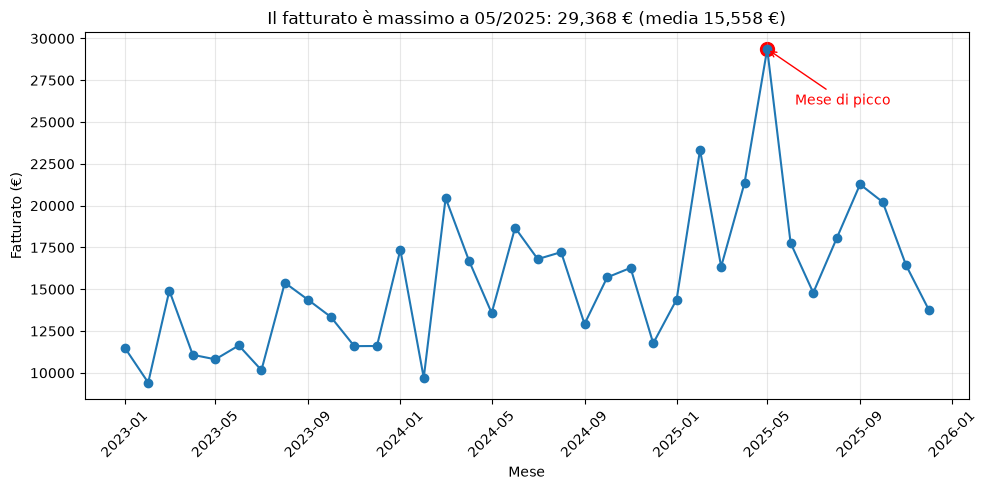

In [43]:
### 1. Matplotlib: grafico a linee del fatturato mensile del Task 3c con titolo etichette degli assi con unità (euro) e mese di picco evidenziato con un'annotazione

# creo la colonna con la data del mese
monthly["Periodo"] = pd.to_datetime(monthly[["Year", "Month"]].assign(day=1))

# trovo il mese di picco
riga_picco = monthly["Revenue"].idxmax()
mese_picco = monthly.loc[riga_picco, "Periodo"]
valore_picco = monthly.loc[riga_picco, "Revenue"]

# calcolo la media per il titolo
media = monthly["Revenue"].mean()

# titolo che dice il risultato
titolo = f"Il fatturato è massimo a {mese_picco:%m/%Y}: {valore_picco:,.0f} € (media {media:,.0f} €)"

# plot
plt.figure(figsize=(10, 5))
plt.plot(monthly["Periodo"], monthly["Revenue"], marker="o")

# evidenzio il picco con un punto rosso e un'annotazione
plt.scatter(mese_picco, valore_picco, color="red", s=100)
plt.annotate(
    "Mese di picco",
    xy=(mese_picco, valore_picco),
    xytext=(20, -40),
    textcoords="offset points",
    arrowprops=dict(arrowstyle="->", color="red"),
    color="red",
)

# titolo ed etichette degli assi con unità
plt.title(titolo)
plt.xlabel("Mese")
plt.ylabel("Fatturato (€)")
plt.grid(alpha=0.3)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

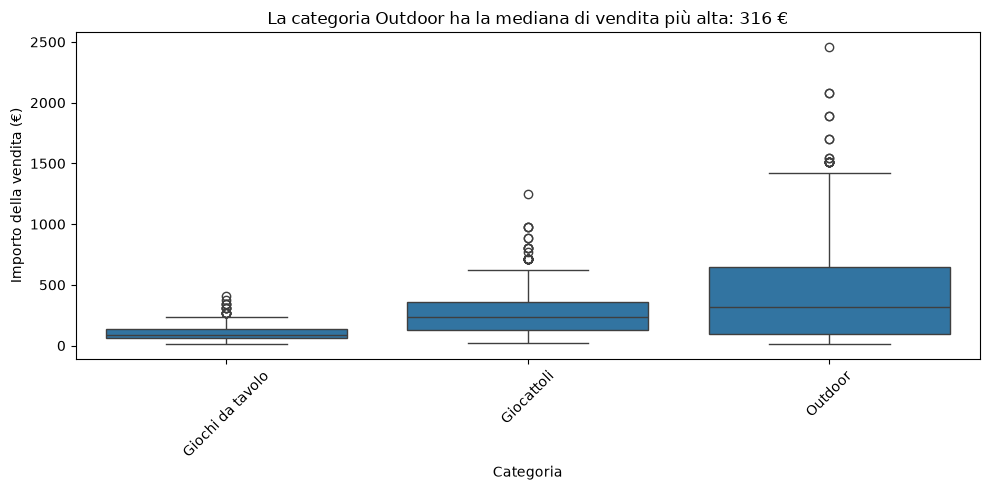

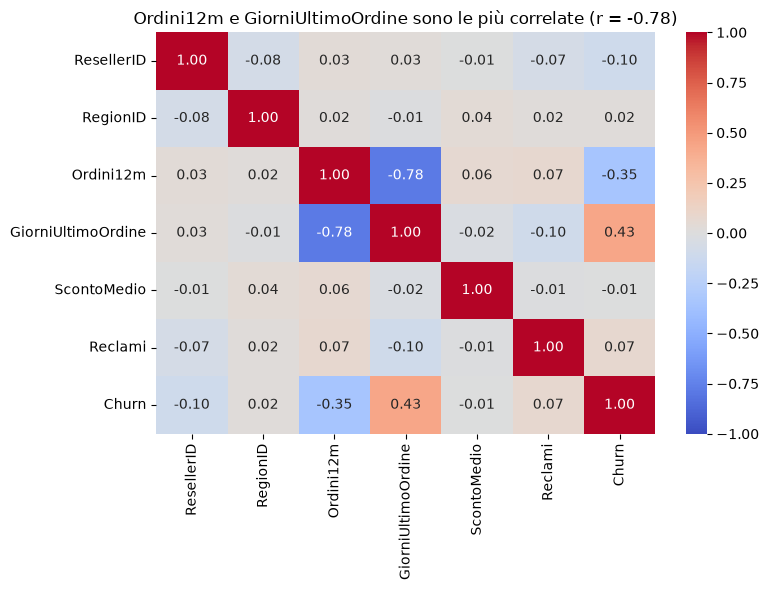

In [ ]:
### 2. Seaborn boxplot di SalesAmount per categoria e heatmap della matrice di correlazione delle variabili numeriche di resellers

# importo resellers
resellers = pd.read_csv("ESERCIZIO_M4-4-2_traccia_finale-resellers.csv")

## boxplot di SalesAmount per categoria

# trovo la categoria con la mediana più alta (serve per il titolo)
mediane = final_merge.groupby("Category")["SalesAmount"].median()
cat_top = mediane.idxmax()
mediana_top = mediane.max()

titolo_box = f"La categoria {cat_top} ha la mediana di vendita più alta: {mediana_top:,.0f} €"

# plot
plt.figure(figsize=(10, 5))
sns.boxplot(data=final_merge, x="Category", y="SalesAmount")
plt.title(titolo_box)
plt.xlabel("Categoria")
plt.ylabel("Importo della vendita (€)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


## heatmap della matrice di correlazione delle variabili numeriche di resellers 

# tengo solo le colonne numeriche di resellers e calcolo la correlazione
corr = resellers.select_dtypes(include="number").corr()

# trovo la coppia di variabili con la correlazione più forte (diagonale esclusa)
coppie = corr.unstack()
coppie = coppie[coppie < 1]
var1, var2 = coppie.abs().idxmax()
valore = corr.loc[var1, var2]

titolo_heat = f"{var1} e {var2} sono le più correlate (r = {valore:.2f})"

# 3. grafico
plt.figure(figsize=(8, 6))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1)
plt.title(titolo_heat)
plt.tight_layout()
plt.show()

In [50]:
### Plotly: grafico a barre interattivo del fatturato per stato, con quantità totale e numero di transazioni nel tooltip(hover).

# raggruppo per stato: fatturato, quantità totale, numero di transazioni
per_stato = (
    final_merge.groupby("State")
    .agg(
        Fatturato=("SalesAmount", "sum"),
        Quantita=("Quantity", "sum"),
        Transazioni=("SalesID", "count"),
    )
    .reset_index()
    .sort_values("Fatturato", ascending=False)
)

# trovo lo stato con il fatturato più alto (serve per il titolo)
stato_top = per_stato.iloc[0]["State"]
fatturato_top = per_stato.iloc[0]["Fatturato"]
quota = fatturato_top / per_stato["Fatturato"].sum() * 100

titolo = f"{stato_top} genera il fatturato più alto: {fatturato_top:,.0f} € ({quota:.0f}% del totale)"

# grafico a barre
fig = px.bar(
    per_stato,
    x="State",
    y="Fatturato",
    title=titolo,
    labels={"State": "Stato", "Fatturato": "Fatturato (€)"},
    hover_data={"Quantita": ":,.0f", "Transazioni": ":,", "Fatturato": ":,.0f"},
)

# evidenzio la barra più alta (la prima, perché ho ordinato)
colori = ["red"] + ["steelblue"] * (len(per_stato) - 1)
fig.update_traces(marker_color=colori)

fig.update_layout(xaxis_tickangle=-45)
fig.show()


## TASK 5 - Correlazione e regressione lineare 
Stimare il fatturato con modello linearee e usarlo per una previsione dei mesi successivi

**R²**

- **Cos'è:** è un numero che dice quanto bene il modello di regressione riesce a "seguire" i dati reali.
- **Intervallo dei valori:** va da 0 a 1 (spesso letto come 0%-100%). Vicino a 1 il modello spiega quasi tutta la variazione del fatturato, vicino a 0 non spiega quasi nulla. Sul test può anche risultare negativo, e allora il modello sbaglia più di una semplice media.
- **Cosa misura:** la quota di variazione della variabile da prevedere (es. il fatturato) che è spiegata dalle variabili usate nel modello. Esempio: R² = 0,80 significa che il modello spiega circa l'80% delle variazioni del fatturato, il restante 20% dipende da altro.

**Perché una correlazione o un R² alto non dimostrano causa ed effetto**

- Correlazione e R² dicono solo che due variabili **si muovono insieme**, non che una **provochi** l'altra.


In [52]:
### 1. con corr() calcolare le correlazione tra fatturato mensile, quantità mensile e numero di rivenditori attivi nel mese, indicando la coppia più correlata. 

# converto la colonna date 
final_merge["SalesDate"] = pd.to_datetime(final_merge["SalesDate"])
# creo la colonna del mese 
final_merge["Mese"] = final_merge["SalesDate"].dt.to_period("M")

# per ogni mese calcolo le tre misure
mensile = (
    final_merge.groupby("Mese")
    .agg(
        Fatturato=("SalesAmount", "sum"),
        Quantita=("Quantity", "sum"),
        RivenditoriAttivi=("ResellerID", "nunique"),
    )
    .reset_index()
)
display(mensile)

# matrice di correlazione (tolgo la colonna Mese, non è numerica)
corr = mensile[["Fatturato", "Quantita", "RivenditoriAttivi"]].corr()
display(corr)

# trovo la coppia più correlata (diagonale esclusa)
coppie = corr.unstack()
coppie = coppie[coppie < 1]
var1, var2 = coppie.abs().idxmax()
valore = corr.loc[var1, var2]

print(f"Coppia più correlata: {var1} e {var2} (r = {valore:.2f})")

,Mese,Fatturato,Quantita,RivenditoriAttivi
0,2023-01,11499.8,238.0,56
1,2023-02,9414.9,184.0,46
2,2023-03,14917.2,243.0,51
3,2023-04,11077.9,223.0,52
4,2023-05,10806.7,197.0,52
5,2023-06,11637.3,191.0,47
6,2023-07,10161.0,183.0,43
7,2023-08,15387.5,231.0,45
8,2023-09,14361.2,220.0,46
9,2023-10,13340.5,210.0,49


,Fatturato,Quantita,RivenditoriAttivi
Fatturato,1.000000,0.854112,0.489228
Quantita,0.854112,1.000000,0.617511
RivenditoriAttivi,0.489228,0.617511,1.000000


Coppia più correlata: Fatturato e Quantita (r = 0.85)


In [57]:
### 2. dopo train_test_split(test_size=0.2, random_state=42), stimare con LinearRegression una regressione semplice (fatturato su indice del mese) e una multipla (indice del mese, quantità, rivenditori attivi)

# indice del mese
mensile = mensile.sort_values("Mese").reset_index(drop=True)
mensile["IndiceMese"] = range(1, len(mensile) + 1)

# split
train, test = train_test_split(mensile, test_size=0.2, random_state=42)
y_train = train["Fatturato"]
y_test = test["Fatturato"]

# regressione semplice
X_train_s = train[["IndiceMese"]]
X_test_s = test[["IndiceMese"]]
modello_s = LinearRegression()
modello_s.fit(X_train_s, y_train)

# regressione multipla
colonne = ["IndiceMese", "Quantita", "RivenditoriAttivi"]
X_train_m = train[colonne]
X_test_m = test[colonne]
modello_m = LinearRegression()
modello_m.fit(X_train_m, y_train)


,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](3,)","[ -67.97, 82.86,-213.17]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](3,)","['IndiceMese','Quantita','RivenditoriAttivi']"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,5465
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,3
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(3)


In [56]:
### 3. riportare coef_, intercept_ e R quadro su train e test per i due modelli; prevedere con il modello semplice il fatturato dei 3 mesi successivi all'ultimo disponibile 

## Riepilogo Modelli
print("MODELLO SEMPLICE (IndiceMese)")
print(f"coef_:      {modello_s.coef_}")
print(f"intercept_: {modello_s.intercept_:,.2f}")
print(f"R² train:   {modello_s.score(X_train_s, y_train):.3f}")
print(f"R² test:    {modello_s.score(X_test_s, y_test):.3f}")

print("\nMODELLO MULTIPLO (IndiceMese, Quantita, RivenditoriAttivi)")
print(f"coef_:      {modello_m.coef_}")
print(f"intercept_: {modello_m.intercept_:,.2f}")
print(f"R² train:   {modello_m.score(X_train_m, y_train):.3f}")
print(f"R² test:    {modello_m.score(X_test_m, y_test):.3f}")

## Previsione prossimi 3 mesi 

# ultimo indice e ultimo mese disponibili
ultimo_indice = mensile["IndiceMese"].max()
ultimo_mese = mensile["Mese"].max()

# indici dei 3 mesi futuri (devono essere un DataFrame con lo stesso nome di colonna)
futuro = pd.DataFrame({"IndiceMese": [ultimo_indice + 1, ultimo_indice + 2, ultimo_indice + 3]})

# etichette dei mesi futuri (Mese è un Period, quindi posso sommare i mesi)
futuro["Mese"] = [ultimo_mese + 1, ultimo_mese + 2, ultimo_mese + 3]

# previsione con il modello semplice
futuro["FatturatoPrevisto"] = modello_s.predict(futuro[["IndiceMese"]])

display(futuro)

MODELLO SEMPLICE (IndiceMese)
coef_:      [303.57718604]
intercept_: 10,602.53
R² train:   0.477
R² test:    -1.879

MODELLO MULTIPLO (IndiceMese, Quantita, RivenditoriAttivi)
coef_:      [ -67.96574141   82.86137021 -213.16586236]
intercept_: 5,465.05
R² train:   0.845
R² test:    -1.075


,IndiceMese,Mese,FatturatoPrevisto
0,37,2026-01,21834.884948
1,38,2026-02,22138.462134
2,39,2026-03,22442.039321


## TASK 6a - Classificazione del churn dei rivenditori 
prevedere quali rivenditori smetteranno di ordinare con una regressione logistica e valutare gli errori del modello 

**Apprendimento supervisionato**

- **Dati richiesti:** dati con la risposta già nota. Ogni riga ha le variabili di input (X) e anche l'etichetta da prevedere (y), cioè il "risultato giusto".
- **Obiettivo:** imparare dagli esempi passati per prevedere la risposta su dati nuovi. Se la risposta è una categoria si parla di classificazione, se è un numero di regressione.

**Apprendimento non supervisionato**

- **Dati richiesti:** dati senza etichetta. Ci sono solo le variabili di input, nessuna risposta giusta da imparare.
- **Obiettivo:** trovare da soli una struttura nei dati, ad esempio gruppi di righe simili tra loro (clustering). Non si "prevede" qualcosa, si scopre qualcosa.

**nel supervisionato il modello impara da esempi con la risposta (c'è `Churn`), nel non supervisionato deve trovare i gruppi da solo (non c'è nessuna risposta).**

In [59]:
### 1. separare X (Ordini12m, GiorniUltimoOrdine, ScontoMedio, Reclami) e y (Churn); applicare train_testsplit con stratify=y e StandardScaler con fit solo sul training set

# separo le variabili di input (X) dalla variabile da prevedere (y)
X = resellers[["Ordini12m", "GiorniUltimoOrdine", "ScontoMedio", "Reclami"]]
y = resellers["Churn"]

# divido in train (80%) e test (20%), mantenendo la stessa proporzione di Churn
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# standardizzo fit solo sul train, poi trasformo train e test
scaler = StandardScaler()
X_train_sc = scaler.fit_transform(X_train)
X_test_sc = scaler.transform(X_test)

# controllo che la proporzione di Churn sia simile nei due insiemi
print(y_train.value_counts(normalize=True))
print(y_test.value_counts(normalize=True))

Churn
0    0.7625
1    0.2375
Name: proportion, dtype: float64
Churn
0    0.766667
1    0.233333
Name: proportion, dtype: float64


Matrice di confusione, soglia 0.5
[[42  4]
 [10  4]]

Matrice di confusione, soglia 0.3
[[36 10]
 [ 4 10]]


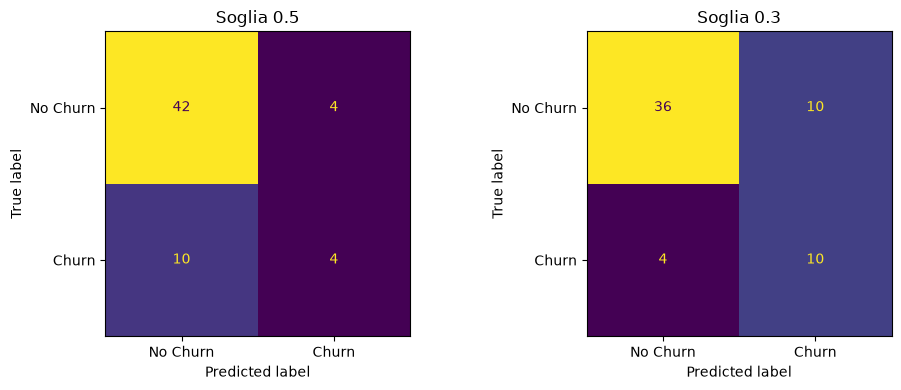

In [62]:
### 2. addestrare LogisticRegression, ottenere predict() e predict_proba() e costruire la matrice di confusione con soglia 0.5 e con soglia 0.3

# addestro il modello sui dati standardizzati del train
modello = LogisticRegression(random_state=42)
modello.fit(X_train_sc, y_train)

# predict(): classe prevista (0 o 1), usa in automatico la soglia 0.5
y_pred = modello.predict(X_test_sc)

# predict_proba(): probabilità di ogni classe; prendo la colonna 1 = probabilità di Churn
y_proba = modello.predict_proba(X_test_sc)[:, 1]

# soglia 0.5 e soglia 0.3 applicate alle probabilità
y_pred_05 = (y_proba >= 0.5).astype(int)
y_pred_03 = (y_proba >= 0.3).astype(int)

# matrici di confusione
cm_05 = confusion_matrix(y_test, y_pred_05)
cm_03 = confusion_matrix(y_test, y_pred_03)

print("Matrice di confusione, soglia 0.5")
print(cm_05)
print("\nMatrice di confusione, soglia 0.3")
print(cm_03)

# grafico delle due matrici affiancate
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
ConfusionMatrixDisplay(cm_05, display_labels=["No Churn", "Churn"]).plot(ax=axes[0], colorbar=False)
axes[0].set_title("Soglia 0.5")
ConfusionMatrixDisplay(cm_03, display_labels=["No Churn", "Churn"]).plot(ax=axes[1], colorbar=False)
axes[1].set_title("Soglia 0.3")
plt.tight_layout()
plt.show()

In [64]:
### 3. calcolare Accuracy, Precision e Recall per le due soglie e confrontare l'Accuracy con la baseline Churn = 0

# calcolo le tre metriche per ogni soglia
risultati = pd.DataFrame({
    "Soglia": [0.5, 0.3],
    "Accuracy": [
        accuracy_score(y_test, y_pred_05),
        accuracy_score(y_test, y_pred_03),
    ],
    "Precision": [
        precision_score(y_test, y_pred_05, zero_division=0),
        precision_score(y_test, y_pred_03, zero_division=0),
    ],
    "Recall": [
        recall_score(y_test, y_pred_05),
        recall_score(y_test, y_pred_03),
    ],
}).round(3)

display(risultati)

# baseline: prevedo sempre Churn = 0 (nessun cliente se ne va)
y_pred_base = [0] * len(y_test)
acc_base = accuracy_score(y_test, y_pred_base)

print(f"Accuracy baseline (sempre Churn = 0): {acc_base:.3f}")
print(f"Accuracy soglia 0.5: {risultati.loc[0, 'Accuracy']:.3f}")
print(f"Accuracy soglia 0.3: {risultati.loc[1, 'Accuracy']:.3f}")

,Soglia,Accuracy,Precision,Recall
0,0.5,0.767,0.5,0.286
1,0.3,0.767,0.5,0.714


Accuracy baseline (sempre Churn = 0): 0.767
Accuracy soglia 0.5: 0.767
Accuracy soglia 0.3: 0.767


In [65]:
### 4. confrontare Accuracy e Recall su train test e classificare il modello come underfitting, buon adattamento o overfitting

# previsioni sul train (stessa soglia 0.5 del modello)
y_pred_train = modello.predict(X_train_sc)

# metriche su train e test
tabella = pd.DataFrame({
    "Insieme": ["Train", "Test"],
    "Accuracy": [
        accuracy_score(y_train, y_pred_train),
        accuracy_score(y_test, y_pred_05),
    ],
    "Recall": [
        recall_score(y_train, y_pred_train),
        recall_score(y_test, y_pred_05),
    ],
}).round(3)

display(tabella)

# differenza train - test (il "gap")
gap_acc = tabella.loc[0, "Accuracy"] - tabella.loc[1, "Accuracy"]
gap_rec = tabella.loc[0, "Recall"] - tabella.loc[1, "Recall"]

print(f"Gap Accuracy (train - test): {gap_acc:.3f}")
print(f"Gap Recall   (train - test): {gap_rec:.3f}")

# classificazione con regola semplice (le soglie sono indicative)
acc_train = tabella.loc[0, "Accuracy"]

if gap_acc > 0.10 or gap_rec > 0.10:
    diagnosi = "OVERFITTING: va molto meglio sul train che sul test"
elif acc_train <= acc_base:
    diagnosi = "UNDERFITTING: non supera nemmeno la baseline, anche sul train"
else:
    diagnosi = "BUON ADATTAMENTO: train e test sono simili e il modello supera la baseline"

print(f"\nDiagnosi: {diagnosi}")

,Insieme,Accuracy,Recall
0,Train,0.775,0.316
1,Test,0.767,0.286


Gap Accuracy (train - test): 0.008
Gap Recall   (train - test): 0.030

Diagnosi: BUON ADATTAMENTO: train e test sono simili e il modello supera la baseline


## TASK 6b - Segmentazione dei rivenditori con K-Means
Suddividere i rivenditori in segmenti omogenei per comportamento d'acquisto e confrontare i segmenti con il churn

**Centroide**
- **Cos'è:** è il "centro" di un cluster, cioè il punto medio di tutti i rivenditori che ne fanno parte. Si calcola facendo la media di ogni variabile sui punti del gruppo.
- **A cosa serve:** K-Means assegna ogni punto al centroide più vicino. Poi ricalcola i centroidi con i nuovi gruppi e ripete finché i gruppi non cambiano più.

**se un cluster contiene tre rivenditori con 10, 20 e 30 ordini, il centroide ha 20 ordini.**

**Inerzia**

- **Cos'è:** un numero che misura quanto i punti sono vicini al centroide del proprio cluster. Si calcola sommando le distanze al quadrato tra ogni punto e il suo centroide.
- **Come si legge:** più è bassa, più i cluster sono compatti. Scende sempre al crescere di k, quindi non si sceglie il valore più basso ma il k del "gomito", dove il calo diventa piccolo.

**K-Means non richiede una colonna y né la divisione train/test**

- **Nessuna colonna y:** K-Means è apprendimento non supervisionato. Non deve prevedere una risposta nota (come `Churn`), deve solo trovare gruppi di punti simili usando le variabili di input. Per questo `fit` riceve solo X.
- **Nessuna divisione train/test:** il train/test serve a controllare se un modello prevede bene dati mai visti, confrontando le previsioni con le risposte vere. Nel clustering non ci sono risposte vere con cui confrontare, quindi non c'è un errore di previsione da misurare sul test. Si raggruppano tutti i dati disponibili e si valuta il risultato guardando i profili dei cluster.

**questo non significa che il clustering sia sempre "giusto". La qualità si controlla con il gomito, con il profilo dei cluster e, se serve, con strumenti come `silhouette_score`.**

In [72]:
### 1. calcolare il fatturato totale per rivenditore da sales con groupby(), standadizzare Ordini12m, GiorniUltimoOrdine e fatturato e calcolare inertia_per k da 1 a 10 con KMeans(n_int=10, random_state=42)

# fatturato totale per rivenditore
fatturato = (
    sales.groupby("ResellerID")["SalesAmount"]
    .sum()
    .reset_index(name="Fatturato")
)

# unisco il fatturato alla tabella che contiene Ordini12m e GiorniUltimoOrdine
dati = resellers.merge(fatturato, on="ResellerID", how="inner")

# tengo solo le tre variabili da usare nel clustering
X = dati[["Ordini12m", "GiorniUltimoOrdine", "Fatturato"]]

# standardizzo (media 0, deviazione standard 1)
scaler = StandardScaler()
X_sc = scaler.fit_transform(X)

# inertia per k da 1 a 10
inertia = []
valori_k = range(1, 11)

for k in valori_k:
    km = KMeans(n_clusters=k, n_init=10, random_state=42)
    km.fit(X_sc)
    inertia.append(km.inertia_)

# tabella dei risultati
tabella_inertia = pd.DataFrame({"k": list(valori_k), "Inertia": inertia}).round(2)
display(tabella_inertia)

C:\Users\SZN\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1428: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=2.
  warnings.warn(
C:\Users\SZN\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1428: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=2.
  warnings.warn(
C:\Users\SZN\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1428: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=2.
  warnings.warn(
C:\Users\SZN\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1428: UserWarning: KMeans is known to have a memory leak on Windows with M

,k,Inertia
0,1,888.00
1,2,430.68
2,3,313.83
3,4,255.36
4,5,225.37
5,6,197.23
6,7,179.93
7,8,163.13
8,9,148.56
9,10,136.14


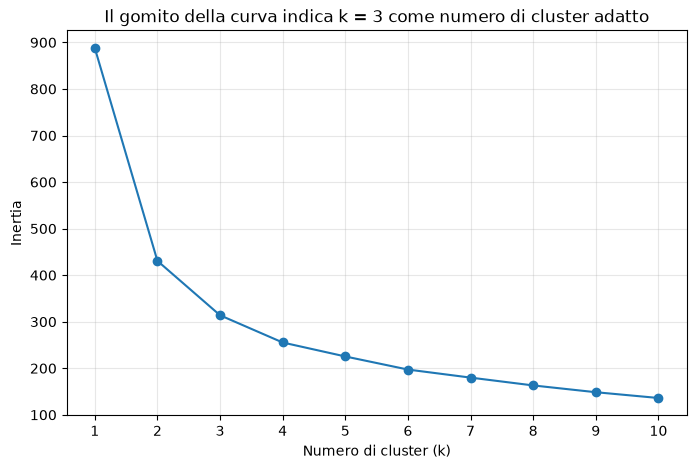

Cluster
0     97
1    142
2     57
Name: count, dtype: int64


C:\Users\SZN\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1428: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=2.
  warnings.warn(


,Ordini12m,GiorniUltimoOrdine,Fatturato
Cluster,,,
0,19.6,46.4,1575.7
1,12.8,139.3,1420.4
2,22.5,37.8,3605.9


In [ ]:
### 2. scegliere k con il metodo del gomito e assegnare i cluster con fit_predict() in una nuova colonna

# grafico del gomito inertia contro k
plt.figure(figsize=(8, 5))
plt.plot(tabella_inertia["k"], tabella_inertia["Inertia"], marker="o")
plt.title("Il gomito della curva indica k = 3 come numero di cluster adatto")  # aggiorna k in base al tuo grafico
plt.xlabel("Numero di cluster (k)")
plt.ylabel("Inertia")
plt.xticks(range(1, 11))
plt.grid(alpha=0.3)
plt.show()

# k scelto guardando il grafico
k_scelto = 3 # dove vedo il gomito 

# addestro KMeans con il k scelto e assegno il cluster a ogni rivenditore
km_finale = KMeans(n_clusters=k_scelto, n_init=10, random_state=42)
dati["Cluster"] = km_finale.fit_predict(X_sc)

# controllo quanti rivenditori ci sono in ogni cluster
print(dati["Cluster"].value_counts().sort_index())

# profilo dei cluster: media delle variabili originali (non standardizzate)
profilo = dati.groupby("Cluster")[["Ordini12m", "GiorniUltimoOrdine", "Fatturato"]].mean().round(1)
display(profilo)

In [74]:
### 3. profilare i cluster con groupby() sulle variabili originali, assegnare un nome a ciascuno e calcolare la quota di churn per cluster

# medie delle variabili originali (non standardizzate) per cluster
profilo = dati.groupby("Cluster").agg(
    NumRivenditori=("ResellerID", "count"),
    Ordini12m=("Ordini12m", "mean"),
    GiorniUltimoOrdine=("GiorniUltimoOrdine", "mean"),
    Fatturato=("Fatturato", "mean"),
).round(1)
display(profilo)

# assegno un nome a ogni cluster guardando la tabella qui sopra
nomi = {
    0: "Clienti fedeli",
    1: "Clienti occasionali",
    2: "Clienti a rischio",
}
dati["NomeCluster"] = dati["Cluster"].map(nomi)

# quota di churn per cluster (Churn è 0/1, quindi la media è la percentuale di churn)
quota_churn = (
    dati.groupby("NomeCluster")["Churn"]
    .mean()
    .mul(100)
    .round(1)
    .sort_values(ascending=False)
)
print("Quota di churn per cluster (%):")
display(quota_churn)

,NumRivenditori,Ordini12m,GiorniUltimoOrdine,Fatturato
Cluster,,,,
0,97,19.6,46.4,1575.7
1,142,12.8,139.3,1420.4
2,57,22.5,37.8,3605.9


Quota di churn per cluster (%):


NomeCluster
Clienti occasionali    40.1
Clienti fedeli          9.3
Clienti a rischio       7.0
Name: Churn, dtype: float64

## TASK 7 - Debugging, refactoring e versioning 

In [81]:
# Caso 1: media del fatturato
totale = 0
for v in sales["SalesAmount"]:
        totale += v
media = totale / len(sales)

## Debugging Caso 1: media del fatturato

**PROMP usato per interrogare Claude**: 
Fai debugging sul seguente codice e generami un commento markdown, in italiano, dove spieghi cosa non funziona, come si corregge e come si verifica.

**Codice originale**

    totale = 0
    for v in sales["SalesAmount"]:
        totale += v
    media = totale / len(sales)

**Cosa non funziona**

- **Valori mancanti (NaN):** la colonna `SalesAmount` contiene 100 valori NaN. Quando il ciclo somma un NaN, `totale` diventa NaN e resta NaN fino alla fine. Il risultato è `media = nan`, senza nessun messaggio di errore, quindi il problema è facile da non notare.
- **Divisore sbagliato:** `len(sales)` conta tutte le righe, comprese quelle senza importo. Anche se si saltassero i NaN nella somma, si dividerebbe per un numero troppo grande e la media risulterebbe più bassa del vero. Il divisore deve contare solo le vendite con importo valido.
- **Dataset vuoto:** se `sales` non avesse righe (ad esempio dopo un filtro troppo restrittivo), `len(sales)` sarebbe 0 e la divisione darebbe `ZeroDivisionError`. Nel nostro dataset non succede, ma è un caso da prevedere.

**Correzione**

    totale = 0
    conteggio = 0

    for v in sales["SalesAmount"]:
        if pd.notna(v):
            totale += v
            conteggio += 1

    media = totale / conteggio if conteggio > 0 else None

**Verifica**

Il risultato del ciclo corretto coincide con `sales["SalesAmount"].mean()`: **294,78 €**. Questo conferma che la media è calcolata solo sulle vendite con importo noto, escludendo le 100 righe con `SalesAmount` mancante.

**Conclusione**

Il codice originale è sintatticamente corretto ma produce un risultato sbagliato (`nan`) perché non gestisce i valori mancanti. Prima di fare calcoli su una colonna è buona pratica controllare i NaN con `isna().sum()`.

In [82]:
# Caso 2: preparazione del modello 
scaler = StandardScaler()
X_s = scaler.fit_transform(X)
X_train, X_test, y_train, y_test = \
    train_test_split(X_s, y)

ValueError: Found input variables with inconsistent numbers of samples: [296, 300]

## Debugging Caso 2: preparazione del modello

**PROMPT usato per interrogare claude**: Fai debugging sul seguente codice e generami un commento markdown, in italiano, dove spieghi cosa non funziona, come si corregge e come si verifica.  

**Codice originale**

    scaler = StandardScaler()
    X_s = scaler.fit_transform(X)
    X_train, X_test, y_train, y_test = \
        train_test_split(X_s, y)

**Cosa non funziona**

- **Data leakage (errore principale):** lo `StandardScaler` viene addestrato (`fit_transform`) su **tutto** `X`, prima della divisione. Media e deviazione standard sono quindi calcolate anche sui dati che finiranno nel test. Il test non è più "mai visto": contiene già informazioni usate nella preparazione, e le metriche risultano più ottimistiche del vero. Il codice non dà nessun errore, quindi il problema è facile da non notare.
- **Ordine sbagliato dei passaggi:** la regola è prima dividere in train e test, poi standardizzare con `fit` solo sul train e `transform` sul test.
- **Manca `random_state`:** senza questo parametro la divisione cambia a ogni esecuzione, quindi i risultati non sono riproducibili. Nell'esercizio si usa `random_state=42`.
- **Manca `test_size`:** il valore predefinito è 0.25. Se la traccia chiede 80/20, va scritto `test_size=0.2`.
- **Manca `stratify=y`:** se `y` è una classificazione con classi sbilanciate (come `Churn`), train e test possono avere proporzioni diverse delle classi. Lo `stratify=y` mantiene la stessa proporzione.

**Correzione**

    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=0.2, random_state=42, stratify=y
    )

    scaler = StandardScaler()
    X_train_sc = scaler.fit_transform(X_train)   # fit SOLO sul train
    X_test_sc = scaler.transform(X_test)         # il test usa media e deviazione del train

**Verifica**

Dopo la correzione, `X_train_sc` ha media circa 0 e deviazione standard circa 1 (controllabile con `X_train_sc.mean(axis=0)` e `X_train_sc.std(axis=0)`), mentre `X_test_sc` ha valori vicini ma non identici a 0 e 1. È normale: il test è stato trasformato con i parametri del train. Inoltre, rilanciando la cella più volte, la divisione resta sempre la stessa grazie a `random_state=42`.

**Conclusione**

Il codice originale funziona senza errori ma produce una valutazione poco affidabile perché lo scaler "vede" il test prima della divisione. Ogni trasformazione che impara qualcosa dai dati (scaler, imputazione, ecc.) va addestrata solo sul train.

In [83]:
# Caso 3: filtro vendite Bikes
alte = df[df["SalesAmount"] > 500 and
          df["Category"] == "Bikes"]

print(alte.shape)

NameError: name 'df' is not defined

## Debugging Caso 3: filtro vendite Bikes

**PROMPT usato per interrogare claude**: Fai debugging sul seguente codice e generami un commento markdown, in italiano, dove spieghi cosa non funziona, come si corregge e come si verifica.

**Codice originale**

    alte = df[df["SalesAmount"] > 500 and
              df["Category"] == "Bikes"]

    print(alte.shape)

**Cosa non funziona**

- **Operatore `and` non valido sulle Series (errore principale):** `df["SalesAmount"] > 500` e `df["Category"] == "Bikes"` non sono due valori True/False, ma due colonne intere di True/False. Python con `and` prova a trasformare ciascuna in un singolo valore di verità e pandas si rifiuta, dando `ValueError: The truth value of a Series is ambiguous`. Per combinare condizioni su colonne si usa `&` (e `|` al posto di `or`).
- **Mancano le parentesi:** con `&` le parentesi attorno a ogni condizione sono obbligatorie, perché `&` ha la precedenza sugli operatori di confronto. Senza parentesi, `df["SalesAmount"] > 500 & df["Category"] == "Bikes"` dà un errore diverso e poco chiaro.
- **Possibili NaN in `SalesAmount`:** nel dataset ci sono 100 valori mancanti. Il confronto `NaN > 500` dà `False`, quindi quelle righe vengono escluse dal filtro senza nessun avviso. Il risultato è corretto, ma conviene saperlo quando si commenta il numero di righe.
- **Possibile problema sulla colonna `Category`:** se nel dataset il valore è scritto in modo diverso (ad esempio `"Bike"`, `"bikes"` o con spazi), il filtro restituisce 0 righe senza errori. Si controlla con `df["Category"].unique()`.

**Correzione**

    alte = df[(df["SalesAmount"] > 500) & (df["Category"] == "Bikes")]

    print(alte.shape)

**Verifica**

- `alte.shape` restituisce `(righe, colonne)`: il primo numero è quante vendite Bikes superano i 500 €.
- Controlla che il filtro sia giusto con `alte["SalesAmount"].min()` (deve essere maggiore di 500) e `alte["Category"].unique()` (deve contenere solo `"Bikes"`).
- Se il risultato è 0 righe, controlla i valori di `df["Category"].unique()`.

**Conclusione**

Il codice originale non funziona: dà `ValueError` perché `and` non si può usare tra colonne di pandas. Per filtrare con più condizioni si usano `&` e `|` con le parentesi attorno a ogni condizione.

In [84]:
# Caso 4: funzione di report
def f(d, x):
    return d[d.iloc[:, 3] > x] \
        .iloc[:, 6].sum()

## Debugging Caso 4: funzione di report

**PROMPT usato per interrogare claude**: Fai debugging sul seguente codice e generami un commento markdown, in italiano, dove spieghi cosa non funziona, come si corregge e come si verifica.

**Codice originale**

    def f(d, x):
        return d[d.iloc[:, 3] > x] \
            .iloc[:, 6].sum()

**Cosa non funziona**

- **Colonne indicate con numeri di posizione (errore principale):** `iloc[:, 3]` e `iloc[:, 6]` selezionano le colonne per posizione, non per nome. Il codice funziona solo se il DataFrame ha esattamente quell'ordine di colonne. Se cambia l'ordine (ad esempio dopo un `merge`, un `drop` o l'aggiunta di una colonna), la funzione filtra e somma colonne sbagliate **senza nessun errore**, restituendo un numero sbagliato ma plausibile.
- **Non si capisce cosa fa:** `f`, `d`, `x` e i numeri 3 e 6 non dicono nulla. Chi legge non sa quale colonna viene filtrata, quale viene sommata, né cosa rappresenta `x`. Se ci sono 7 colonne come in `sales` (SalesID, ProductID, RegionID, ResellerID, SalesDate, Quantity, SalesAmount), la colonna 3 è `ResellerID` e la 6 è `SalesAmount`: filtrare gli ID con `> x` non ha senso come report.
- **Colonna non numerica o con pochi dati:** se la colonna in posizione 3 è una data o un testo, il confronto `> x` dà errore o risultati strani. Se il DataFrame ha meno di 7 colonne, si ottiene `IndexError: single positional indexer is out-of-bounds`.
- **Valori mancanti:** i NaN nella colonna filtrata vengono esclusi dal confronto (`NaN > x` è `False`), mentre `sum()` ignora i NaN nella colonna sommata. Non è un errore, ma conviene saperlo quando si commenta il risultato.
- **Manca la documentazione:** non c'è una docstring che spieghi cosa restituisce la funzione e con quale soglia.
- **Backslash di continuazione:** il `\` funziona, ma è fragile (basta uno spazio dopo e dà `SyntaxError`). È meglio usare parentesi o scrivere il codice su più righe.

**Correzione**

    def somma_importi_sopra_soglia(df, colonna_filtro, colonna_somma, soglia):
        """Somma i valori di colonna_somma per le righe in cui colonna_filtro > soglia."""
        filtrate = df[df[colonna_filtro] > soglia]
        return filtrate[colonna_somma].sum()

    # esempio: totale di SalesAmount per le vendite con Quantity maggiore di 5
    totale = somma_importi_sopra_soglia(sales, "Quantity", "SalesAmount", 5)
    print(f"Fatturato delle vendite con Quantity > 5: {totale:,.2f} €")

**Verifica**

- Controlla il risultato con il calcolo diretto: `sales.loc[sales["Quantity"] > 5, "SalesAmount"].sum()` deve dare lo stesso numero.
- Prova a cambiare l'ordine delle colonne (`sales[sales.columns[::-1]]`): la versione con i nomi dà lo stesso risultato, quella con `iloc` no.
- Se un nome di colonna è scritto male, la nuova funzione dà `KeyError` con il nome sbagliato, quindi l'errore è visibile subito.

**Conclusione**

Il codice originale funziona, ma è fragile: usa posizioni numeriche al posto dei nomi, quindi può restituire un risultato sbagliato senza avvisare. Usare i nomi delle colonne, nomi di funzione e parametri chiari e una docstring rende il codice leggibile e sicuro da modificare.